# Zollman (2009) Simulation Rewrite
## Written by: Tim Luft
## Co-written with: Gemini 3.1 Pro

# 0. Imports

In [1]:
# Imports
import sys
import numpy as np
import random as rand
import networkx as nx


# 1. Setup

In [ ]:
# Simulation Environment Variables

## Number of trials per round per agent
num_trials = 100

## Hardcap on the number of rounds
num_rounds = 1000

## Specification of the size of the network of agents (i.e., number of agents in the network)
network_size = 10

## Number of arms/theories in the bandit problem
num_arms = 2

## Possible Network Configs (use if iterating through all configs of interest)
poss_net_configs = ["cycle", "wheel", "complete"]

## Single network config (use if looking at a single config)
single_net_config = "cycle"

In [ ]:
# Agent Initialization

# 2. Simplest Possible One-Arm Bandit Updating

In [3]:
# 1. The Starting State: A flat prior (1 success, 1 failure)
agent_belief = {"Theory A": {"alpha": 1, "beta": 1}}
print("Starting belief:", agent_belief)

# 2. The Experiment: We hardcode a success
reward = 1 

# 3. The Belief Update
if reward == 1:
    agent_belief["Theory A"]["alpha"] += 1
else:
    agent_belief["Theory A"]["beta"] += 1

# 4. The Output
print("Updated belief: ", agent_belief)

Starting belief: {'Theory A': {'alpha': 1, 'beta': 1}}
Updated belief:  {'Theory A': {'alpha': 2, 'beta': 1}}


# 3. Simplest Possible Multiple Round One-Arm Bandit Updating

In [5]:
num_rounds = 5

agent_belief = {
    "Theory A": {"alpha": 1, "beta": 1}
}
print("Starting belief: ", agent_belief)

reward = 1

for i in range(num_rounds):
    if reward == 1:
        agent_belief["Theory A"]["alpha"] += 1
    else:
        agent_belief["Theory A"]["beta"] += 1

print("Updated belief: ", agent_belief)



Starting belief:  {'Theory A': {'alpha': 1, 'beta': 1}}
Updated belief:  {'Theory A': {'alpha': 6, 'beta': 1}}


# 4. Simple Probabilistic Multiple Round One-Arm Bandit Updating

In [14]:
import random

true_p = 0.7

agent_belief = {
    "Theory A": {"alpha": 1, "beta": 1}
}
print("Starting belief: ", agent_belief)

num_rounds = 10

for i in range(num_rounds):
    roll = random.random()
    if roll < true_p:
        agent_belief["Theory A"]["alpha"] += 1
    else:
        agent_belief["Theory A"]["beta"] += 1

print("Updated belief: ", agent_belief)


Starting belief:  {'Theory A': {'alpha': 1, 'beta': 1}}
Updated belief:  {'Theory A': {'alpha': 8, 'beta': 4}}


# 5. Simple Probabilistic Multiple Round Two-Arm Bandit Updating (with graphing)

Starting belief:  {'Theory A': {'alpha': 1, 'beta': 1}, 'Theory B': {'alpha': 1, 'beta': 1}}
Updated belief:  {'Theory A': {'alpha': 683, 'beta': 302}, 'Theory B': {'alpha': 8, 'beta': 11}}


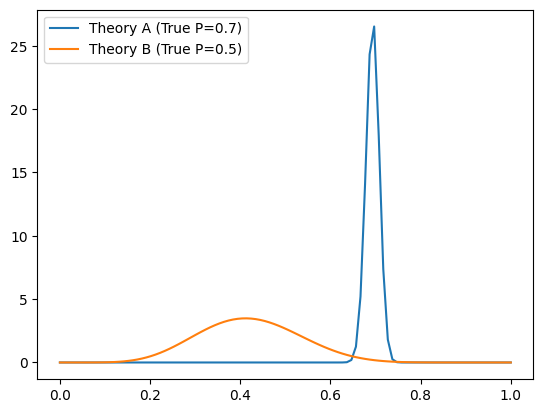

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Agent Initialization
agent_belief = {
    "Theory A": {"alpha": 1, "beta": 1},
    "Theory B": {"alpha": 1, "beta": 1}
}
print("Starting belief: ", agent_belief)

# Simulation Environment Setup
true_p_A = 0.7
true_p_B = 0.5

num_rounds = 100

# Running the Simulation
for i in range(num_rounds):
    sample_A = random.betavariate(agent_belief["Theory A"]["alpha"], agent_belief["Theory A"]["beta"])
    sample_B = random.betavariate(agent_belief["Theory B"]["alpha"], agent_belief["Theory B"]["beta"])
    roll = random.random()

    if sample_A >= sample_B:
        if roll < true_p_A:
            agent_belief["Theory A"]["alpha"] += 1
        else:
            agent_belief["Theory A"]["beta"] += 1
    else: 
        if roll < true_p_B:
            agent_belief["Theory B"]["alpha"] += 1
        else:
            agent_belief["Theory B"]["beta"] += 1

print("Updated belief: ", agent_belief)

# Graphing the Results
x = np.linspace(0, 1, 100)
y_A = beta.pdf(x, agent_belief["Theory A"]["alpha"], agent_belief["Theory A"]["beta"])
y_B = beta.pdf(x, agent_belief["Theory B"]["alpha"], agent_belief["Theory B"]["beta"])

plt.plot(x, y_A, label="Theory A (True P=0.7)")
plt.plot(x, y_B, label="Theory B (True P=0.5)")
plt.legend()
plt.show()

# 7. Networked Probabilistic Multiple Round Two-Arm Bandit Updating (with graphing)

In [28]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
import networkx as nx

# Simulation Environment Setup
true_p_A = 0.5
true_p_B = 0.499

num_pulls = 1000
num_rounds = 10000

# Initializing the network of agents
network_size = 5

agent_net = nx.cycle_graph(network_size)

for node in agent_net.nodes:
    agent_net.nodes[node]['belief'] = {
        "Theory A": {"alpha": 1, "beta": 1},
        "Theory B": {"alpha": 1, "beta": 1}
    }

    print(agent_net.nodes[node]['belief'])


for i in range(num_rounds):
    round_results = {}
    
    # Action Step
    for node in agent_net.nodes:
        agent_belief = agent_net.nodes[node]["belief"]
        sample_A = random.betavariate(agent_belief["Theory A"]["alpha"], agent_belief["Theory A"]["beta"])
        sample_B = random.betavariate(agent_belief["Theory B"]["alpha"], agent_belief["Theory B"]["beta"])

        if sample_A >= sample_B:
            chosen_theory = "Theory A"
            successes = np.random.binomial(num_pulls, true_p_A)
            failures = num_pulls - successes
        else: 
            chosen_theory = "Theory B"
            successes = np.random.binomial(num_pulls, true_p_A)
            failures = num_pulls - successes
        
        round_results[node] = {"theory": chosen_theory, "successes": successes, "failures": failures}

    # Updating Step
    for node in agent_net.nodes:
        agent_belief = agent_net.nodes[node]["belief"]

        neighbors = list(agent_net.neighbors(node))

        observable_nodes = [node] + neighbors

        for o_node in observable_nodes:
            o_result = round_results[o_node]
            
            if o_result["theory"] == "Theory A":
                agent_belief["Theory A"]["alpha"] += o_result["successes"]
                agent_belief["Theory A"]["beta"] += o_result["failures"]
            else:
                agent_belief["Theory B"]["alpha"] += o_result["successes"]
                agent_belief["Theory B"]["beta"] += o_result["failures"]


    print("Updated belief: ", agent_belief)
    print(round_results)
    


{'Theory A': {'alpha': 1, 'beta': 1}, 'Theory B': {'alpha': 1, 'beta': 1}}
{'Theory A': {'alpha': 1, 'beta': 1}, 'Theory B': {'alpha': 1, 'beta': 1}}
{'Theory A': {'alpha': 1, 'beta': 1}, 'Theory B': {'alpha': 1, 'beta': 1}}
{'Theory A': {'alpha': 1, 'beta': 1}, 'Theory B': {'alpha': 1, 'beta': 1}}
{'Theory A': {'alpha': 1, 'beta': 1}, 'Theory B': {'alpha': 1, 'beta': 1}}
Updated belief:  {'Theory A': {'alpha': 503, 'beta': 499}, 'Theory B': {'alpha': 946, 'beta': 1056}}
{0: {'theory': 'Theory A', 'successes': 502, 'failures': 498}, 1: {'theory': 'Theory B', 'successes': 520, 'failures': 480}, 2: {'theory': 'Theory B', 'successes': 532, 'failures': 468}, 3: {'theory': 'Theory B', 'successes': 482, 'failures': 518}, 4: {'theory': 'Theory B', 'successes': 463, 'failures': 537}}
Updated belief:  {'Theory A': {'alpha': 1481, 'beta': 1521}, 'Theory B': {'alpha': 1439, 'beta': 1563}}
{0: {'theory': 'Theory B', 'successes': 493, 'failures': 507}, 1: {'theory': 'Theory B', 'successes': 523, 'f

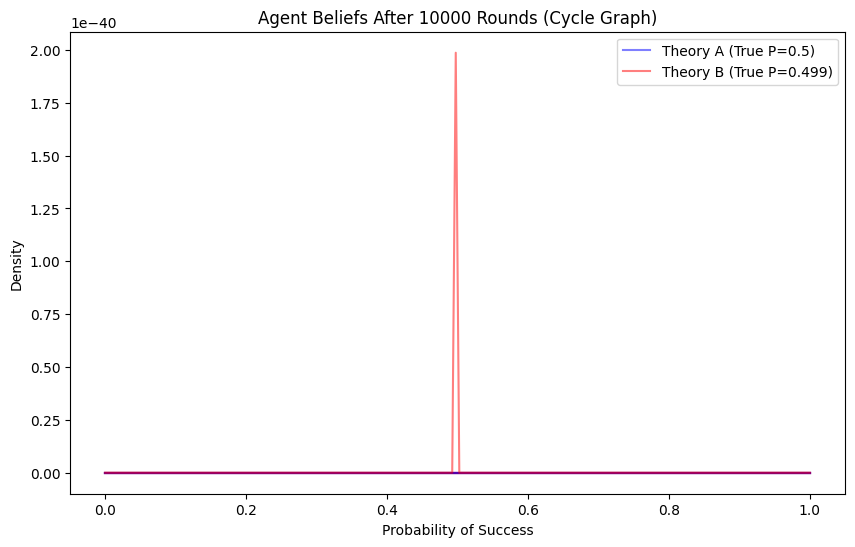

In [29]:
# Visualizing the results
# === Graphing the Entire Network ===
plt.figure(figsize=(10, 6))
x = np.linspace(0, 1, 200)

for node in agent_net.nodes:
    agent_belief = agent_net.nodes[node]["belief"]
    
    # Calculate PDFs
    y_A = beta.pdf(x, agent_belief["Theory A"]["alpha"], agent_belief["Theory A"]["beta"])
    y_B = beta.pdf(x, agent_belief["Theory B"]["alpha"], agent_belief["Theory B"]["beta"])
    
    # Plot Theory A (Blue) and Theory B (Red)
    # We only add labels to node 0 so the legend doesn't duplicate 5 times
    if node == 0:
        plt.plot(x, y_A, color='blue', alpha=0.5, label=f"Theory A (True P={true_p_A})")
        plt.plot(x, y_B, color='red', alpha=0.5, label=f"Theory B (True P={true_p_B})")
    else:
        plt.plot(x, y_A, color='blue', alpha=0.5)
        plt.plot(x, y_B, color='red', alpha=0.5)

plt.title("Agent Beliefs After 10000 Rounds (Cycle Graph)")
plt.xlabel("Probability of Success")
plt.ylabel("Density")
plt.legend()
plt.show()

# 8. Zollman (2009) Full Recreation

In [69]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
import networkx as nx
import pandas as pd

def run_Zollman_sim(topology, net_size, n_rounds, n_pulls, t_p_A, t_p_B, max_prior):

    if topology.upper() == "CYCLE":
        agent_net = nx.cycle_graph(net_size)
    elif topology.upper() == "WHEEL":
        agent_net = nx.wheel_graph(net_size)
    else:
        agent_net = nx.complete_graph(net_size)

    for node in agent_net.nodes:
        agent_net.nodes[node]['belief'] = {
            "Theory A": {"alpha": random.uniform(0, max_prior), "beta": random.uniform(0, max_prior)},
            "Theory B": {"alpha": random.uniform(0, max_prior), "beta": random.uniform(0, max_prior)}
        }

        # print(agent_net.nodes[node]['belief'])

    for i in range(n_rounds):
        round_results = {}
        
        # Action Step
        for node in agent_net.nodes:
            agent_belief = agent_net.nodes[node]["belief"]

            ev_A = agent_belief["Theory A"]["alpha"] / (agent_belief["Theory A"]["alpha"] + agent_belief["Theory A"]["beta"])
            ev_B = agent_belief["Theory B"]["alpha"] / (agent_belief["Theory B"]["alpha"] + agent_belief["Theory B"]["beta"])

            if ev_A > ev_B:
                chosen_theory = "Theory A"
            elif ev_B > ev_A:
                chosen_theory = "Theory B"
            else:
                chosen_theory = random.choice(["Theory A", "Theory B"])

            if chosen_theory == "Theory A":
                successes = np.random.binomial(n_pulls, t_p_A)
                failures = n_pulls - successes
            else: 
                successes = np.random.binomial(n_pulls, t_p_B)
                failures = n_pulls - successes
            
            round_results[node] = {"theory": chosen_theory, "successes": successes, "failures": failures}

        # Updating Step
        for node in agent_net.nodes:
            agent_belief = agent_net.nodes[node]["belief"]

            neighbors = list(agent_net.neighbors(node))

            observable_nodes = [node] + neighbors

            for o_node in observable_nodes:
                o_result = round_results[o_node]
                
                if o_result["theory"] == "Theory A":
                    agent_belief["Theory A"]["alpha"] += o_result["successes"]
                    agent_belief["Theory A"]["beta"] += o_result["failures"]
                else:
                    agent_belief["Theory B"]["alpha"] += o_result["successes"]
                    agent_belief["Theory B"]["beta"] += o_result["failures"]
        
        choices = [round_results[node]["theory"] for node in agent_net.nodes]
        
        # If there is only 1 unique choice in the list, everyone agrees
        if len(set(choices)) == 1:
            break  # Exit the round loop immediately

    # === Evaluate Convergence ===
    final_belief = agent_net.nodes[0]["belief"]
    
    exp_A = final_belief["Theory A"]["alpha"] / (final_belief["Theory A"]["alpha"] + final_belief["Theory A"]["beta"])
    exp_B = final_belief["Theory B"]["alpha"] / (final_belief["Theory B"]["alpha"] + final_belief["Theory B"]["beta"])
    
    # DIAGNOSTIC PRINT
    # print(f"DEBUG: exp_A = {exp_A:.4f}, exp_B = {exp_B:.4f}")
    
    return exp_A > exp_B


        # print("Updated belief: ", agent_belief)
        # print(round_results)



## Figure 3 Recreation

Running Figure 3 Diagnostics (Network Size vs. Convergence)...
This may take a few minutes depending on your CPU.

Processed Cycle Size 3: 52.31%
Processed Cycle Size 4: 54.02%
Processed Cycle Size 5: 57.95%
Processed Cycle Size 6: 62.46000000000001%
Processed Cycle Size 7: 67.57%
Processed Cycle Size 8: 71.83%
Processed Cycle Size 9: 77.41%
Processed Cycle Size 10: 81.43%
Processed Cycle Size 11: 83.95%
Processed Wheel Size 3: 52.26%
Processed Wheel Size 4: 52.81%
Processed Wheel Size 5: 54.64%
Processed Wheel Size 6: 56.35%
Processed Wheel Size 7: 59.53000000000001%
Processed Wheel Size 8: 61.370000000000005%
Processed Wheel Size 9: 65.2%
Processed Wheel Size 10: 68.65%
Processed Wheel Size 11: 70.41%
Processed Complete Size 3: 51.57000000000001%
Processed Complete Size 4: 53.559999999999995%
Processed Complete Size 5: 52.839999999999996%
Processed Complete Size 6: 53.26%
Processed Complete Size 7: 54.71%
Processed Complete Size 8: 54.279999999999994%
Processed Complete Size 9: 54.0%

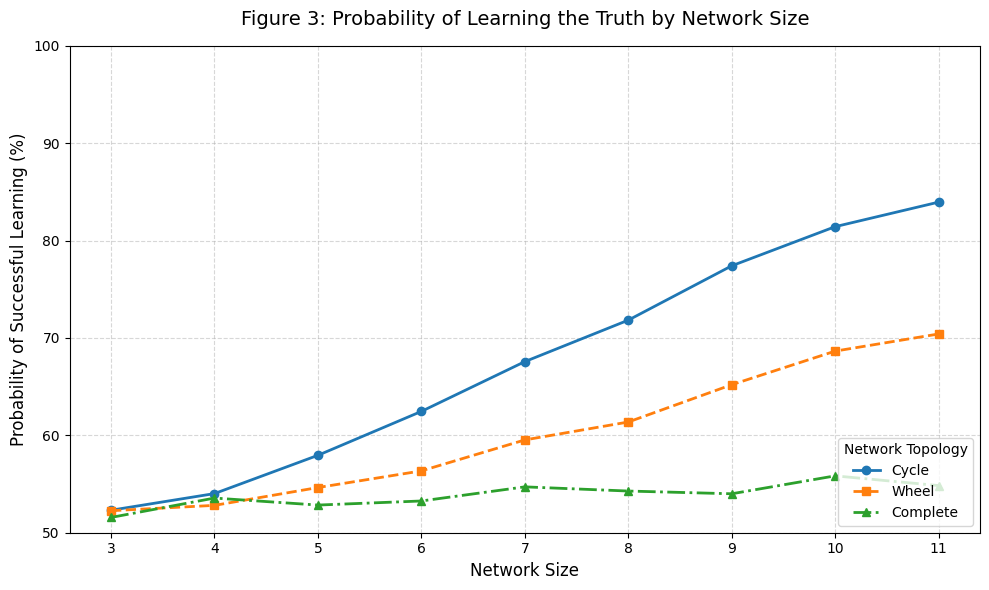

In [70]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Experimental Parameters
topologies = ["Cycle", "Wheel", "Complete"]
sizes = range(3, 12)  # Network sizes from 3 to 11
runs_per_config = 10000 
max_prior_bound = 4

results_data = []

print("Running Figure 3 Diagnostics (Network Size vs. Convergence)...")
print("This may take a few minutes depending on your CPU.\n")

# 2. The Data Pipeline
for topo in topologies:
    for size in sizes:
        success_count = 0
        
        for _ in range(runs_per_config):
            # run_Zollman_sim(topology, size, rounds, pulls, true_A, true_B, max_prior)
            if run_Zollman_sim(topo, size, 10000, 1000, 0.5, 0.499, max_prior_bound):
                success_count += 1
                
        win_rate = (success_count / runs_per_config) * 100
        print(f"Processed {topo} Size {size}: {win_rate}%")
        
        results_data.append({
            "Topology": topo,
            "Network Size": size,
            "Truth Found (%)": win_rate
        })

# 3. Create DataFrame and Pivot for a Line Chart
df = pd.DataFrame(results_data)
df_pivot = df.pivot(index="Network Size", columns="Topology", values="Truth Found (%)")

# 4. Matplotlib Figure 3 Replication
plt.figure(figsize=(10, 6))

# Plotting each line with distinct markers to match academic formatting
plt.plot(df_pivot.index, df_pivot['Cycle'], marker='o', linestyle='-', linewidth=2, label='Cycle')
plt.plot(df_pivot.index, df_pivot['Wheel'], marker='s', linestyle='--', linewidth=2, label='Wheel')
plt.plot(df_pivot.index, df_pivot['Complete'], marker='^', linestyle='-.', linewidth=2, label='Complete')

plt.title("Figure 3: Probability of Learning the Truth by Network Size", fontsize=14, pad=15)
plt.xlabel("Network Size", fontsize=12)
plt.ylabel("Probability of Successful Learning (%)", fontsize=12)

# Set X-axis to show every integer step
plt.xticks(df_pivot.index)
# Standardize Y-axis so we can compare across different diagnostic charts
plt.ylim(50, 100) 

plt.legend(title="Network Topology", loc="lower right")
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

## Figure 6 Recreation

Running Figure 6 Diagnostics (Dogmatism vs. Convergence)...

Processed Cycle | Max Prior 1000: 88.2%
Processed Cycle | Max Prior 2000: 92.0%
Processed Cycle | Max Prior 3000: 94.6%
Processed Cycle | Max Prior 4000: 94.39999999999999%
Processed Cycle | Max Prior 5000: 94.19999999999999%
Processed Cycle | Max Prior 6000: 94.0%
Processed Cycle | Max Prior 7000: 93.4%
Processed Cycle | Max Prior 8000: 92.0%
Processed Cycle | Max Prior 9000: 94.19999999999999%
Processed Cycle | Max Prior 10000: 94.19999999999999%
Processed Wheel | Max Prior 1000: 88.4%
Processed Wheel | Max Prior 2000: 95.8%
Processed Wheel | Max Prior 3000: 95.0%
Processed Wheel | Max Prior 4000: 96.8%
Processed Wheel | Max Prior 5000: 96.8%
Processed Wheel | Max Prior 6000: 96.39999999999999%
Processed Wheel | Max Prior 7000: 95.6%
Processed Wheel | Max Prior 8000: 97.2%
Processed Wheel | Max Prior 9000: 97.8%
Processed Wheel | Max Prior 10000: 97.0%
Processed Complete | Max Prior 1000: 76.0%
Processed Complete | Max Prio

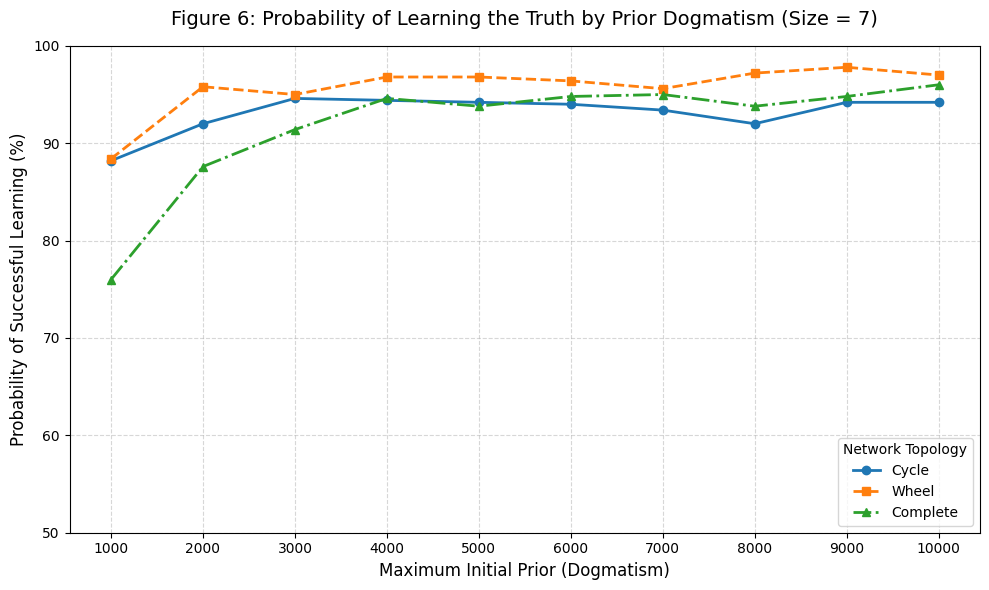

In [71]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Experimental Parameters for Figure 6
topologies = ["Cycle", "Wheel", "Complete"]
max_priors = [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
runs_per_config = 500  

results_data = []

print("Running Figure 6 Diagnostics (Dogmatism vs. Convergence)...")
print("Warning: High priors require more rounds to reach consensus. This will take time.\n")

# 2. The Data Pipeline
for topo in topologies:
    for prior in max_priors:
        success_count = 0
        
        for _ in range(runs_per_config):
            # Network size is locked to 7. 
            # run_Zollman_sim(topology, size, rounds, pulls, true_A, true_B, max_prior)
            if run_Zollman_sim(topo, 7, 10000, 1000, 0.501, 0.500, prior):
                success_count += 1
                
        win_rate = (success_count / runs_per_config) * 100
        print(f"Processed {topo} | Max Prior {prior}: {win_rate}%")
        
        results_data.append({
            "Topology": topo,
            "Max Prior": prior,
            "Truth Found (%)": win_rate
        })

# 3. Create DataFrame and Pivot for a Line Chart
df = pd.DataFrame(results_data)
df_pivot = df.pivot(index="Max Prior", columns="Topology", values="Truth Found (%)")

# 4. Matplotlib Figure 6 Replication
plt.figure(figsize=(10, 6))

plt.plot(df_pivot.index, df_pivot['Cycle'], marker='o', linestyle='-', linewidth=2, label='Cycle')
plt.plot(df_pivot.index, df_pivot['Wheel'], marker='s', linestyle='--', linewidth=2, label='Wheel')
plt.plot(df_pivot.index, df_pivot['Complete'], marker='^', linestyle='-.', linewidth=2, label='Complete')

plt.title("Figure 6: Probability of Learning the Truth by Prior Dogmatism (Size = 7)", fontsize=14, pad=15)
plt.xlabel("Maximum Initial Prior (Dogmatism)", fontsize=12)
plt.ylabel("Probability of Successful Learning (%)", fontsize=12)

# Set X-axis ticks to match the exact intervals tested
plt.xticks(max_priors)
plt.ylim(50, 100) 

plt.legend(title="Network Topology", loc="lower right")
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

Supposedly this graph is actually correct as Zollman's Figure 6 is the result of networks of agents timing out before reaching consensus.

## Figure 7 Recreation

In [73]:
def run_Zollman_variance_tracker(topology, net_size, max_rounds, n_pulls, t_p_A, t_p_B, max_prior):
    # 1. Initialize Network
    if topology.upper() == "CYCLE":
        agent_net = nx.cycle_graph(net_size)
    elif topology.upper() == "WHEEL":
        agent_net = nx.wheel_graph(net_size)
    else:
        agent_net = nx.complete_graph(net_size)

    for node in agent_net.nodes:
        agent_net.nodes[node]['belief'] = {
            "Theory A": {"alpha": random.uniform(0, max_prior), "beta": random.uniform(0, max_prior)},
            "Theory B": {"alpha": random.uniform(0, max_prior), "beta": random.uniform(0, max_prior)}
        }

    variance_timeline = []

    for r in range(max_rounds):
        round_results = {}
        choices_numeric = []
        
        # === PHASE 1: ACTION ===
        for node in agent_net.nodes:
            agent_belief = agent_net.nodes[node]["belief"]
            
            exp_A = agent_belief["Theory A"]["alpha"] / (agent_belief["Theory A"]["alpha"] + agent_belief["Theory A"]["beta"])
            exp_B = agent_belief["Theory B"]["alpha"] / (agent_belief["Theory B"]["alpha"] + agent_belief["Theory B"]["beta"])

            if exp_A > exp_B:
                chosen_theory = "Theory A"
                choices_numeric.append(1)
                successes = np.random.binomial(n_pulls, t_p_A)
            elif exp_B > exp_A:
                chosen_theory = "Theory B"
                choices_numeric.append(0)
                successes = np.random.binomial(n_pulls, t_p_B)
            else:
                chosen_theory = random.choice(["Theory A", "Theory B"])
                choices_numeric.append(1 if chosen_theory == "Theory A" else 0)
                successes = np.random.binomial(n_pulls, t_p_A if chosen_theory == "Theory A" else t_p_B)

            failures = n_pulls - successes
            round_results[node] = {"theory": chosen_theory, "successes": successes, "failures": failures}
            
        # Record the variance of the network's choices for this round
        variance_timeline.append(np.var(choices_numeric))

        # === PHASE 3: CONSENSUS CHECK ===
        if len(set(choices_numeric)) == 1:
            # If they agree, the variance is 0. Pad the rest of the timeline with 0s and exit early.
            remaining_rounds = max_rounds - (r + 1)
            variance_timeline.extend([0.0] * remaining_rounds)
            break
            
        # === PHASE 2: UPDATE ===
        for node in agent_net.nodes:
            agent_belief = agent_net.nodes[node]["belief"]
            observable_nodes = [node] + list(agent_net.neighbors(node))

            for o_node in observable_nodes:
                o_result = round_results[o_node]
                if o_result["theory"] == "Theory A":
                    agent_belief["Theory A"]["alpha"] += o_result["successes"]
                    agent_belief["Theory A"]["beta"] += o_result["failures"]
                else:
                    agent_belief["Theory B"]["alpha"] += o_result["successes"]
                    agent_belief["Theory B"]["beta"] += o_result["failures"]

    return np.array(variance_timeline)

Running Figure 7 Diagnostics (Variance over Time)...
Processed Cycle (Low Prior)
Processed Wheel (Low Prior)
Processed Complete (Low Prior)
Processed Cycle (High Prior)
Processed Wheel (High Prior)
Processed Complete (High Prior)


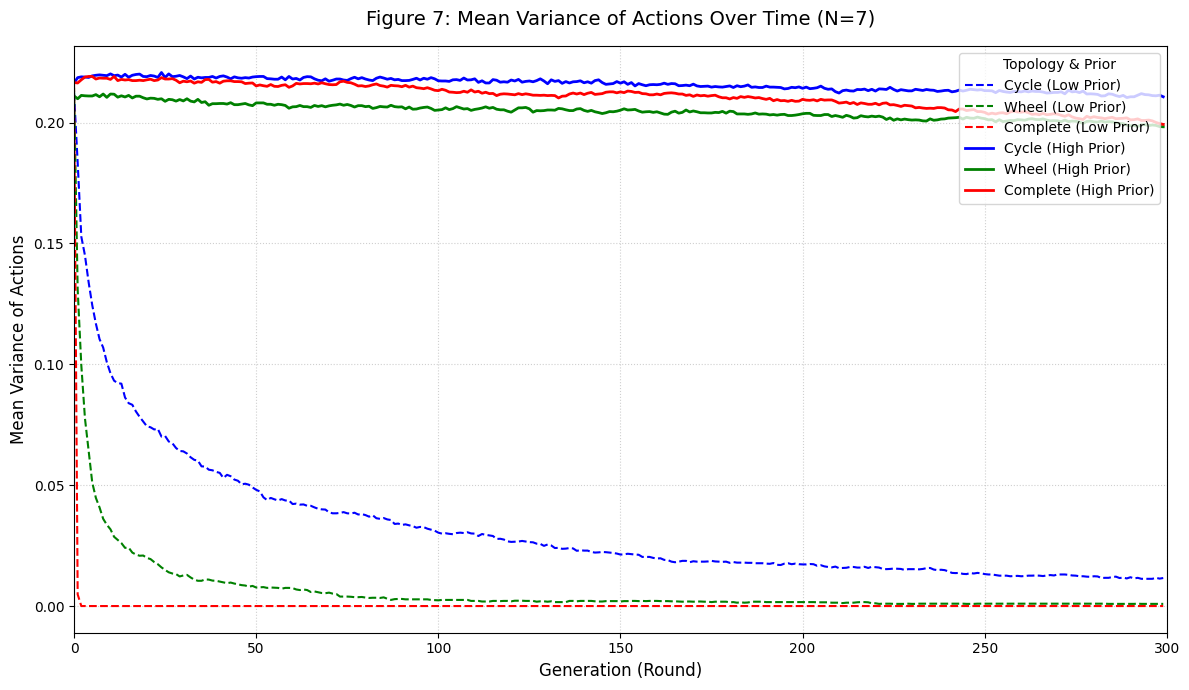

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

topologies = ["Cycle", "Wheel", "Complete"]
priors = {"Low": 4, "High": 10000}
runs_per_config = 500
n_rounds = 300
net_size = 7

print("Running Figure 7 Diagnostics (Variance over Time)...")

# Dictionary to store the averaged timelines
averaged_variances = {}

for prior_label, max_prior in priors.items():
    for topo in topologies:
        # Create an empty matrix to hold the timelines for all runs
        all_runs_matrix = np.zeros((runs_per_config, n_rounds))
        
        for i in range(runs_per_config):
            timeline = run_Zollman_variance_tracker(topo, net_size, n_rounds, 1000, 0.501, 0.500, max_prior)
            all_runs_matrix[i, :] = timeline
            
        # Calculate the mean variance at each round across all runs
        mean_timeline = np.mean(all_runs_matrix, axis=0)
        averaged_variances[f"{topo} - {prior_label} Prior"] = mean_timeline
        print(f"Processed {topo} ({prior_label} Prior)")

# === Matplotlib Figure 7 Replication ===
plt.figure(figsize=(12, 7))

# Plot Low Prior lines (Dashed lines to group them visually)
plt.plot(averaged_variances["Cycle - Low Prior"], label='Cycle (Low Prior)', linestyle='--', color='blue')
plt.plot(averaged_variances["Wheel - Low Prior"], label='Wheel (Low Prior)', linestyle='--', color='green')
plt.plot(averaged_variances["Complete - Low Prior"], label='Complete (Low Prior)', linestyle='--', color='red')

# Plot High Prior lines (Solid lines)
plt.plot(averaged_variances["Cycle - High Prior"], label='Cycle (High Prior)', linestyle='-', linewidth=2, color='blue')
plt.plot(averaged_variances["Wheel - High Prior"], label='Wheel (High Prior)', linestyle='-', linewidth=2, color='green')
plt.plot(averaged_variances["Complete - High Prior"], label='Complete (High Prior)', linestyle='-', linewidth=2, color='red')

plt.title("Figure 7: Mean Variance of Actions Over Time (N=7)", fontsize=14, pad=15)
plt.xlabel("Generation (Round)", fontsize=12)
plt.ylabel("Mean Variance of Actions", fontsize=12)
plt.xlim(0, n_rounds)

plt.legend(title="Topology & Prior", loc="upper right")
plt.grid(axis='both', linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()